# One output file in every format, opened, and how fast each reads

A synthetic combined size-distribution product (30 000 seconds x 128 bins, fixed seed) is written by
the package's **real** faithful writer, then exported to every format the package offers. Each file
is opened and explained, the AI-ready check is run where it applies, and reading speed is measured.

All data here is synthetic. No real or held-out data is read.

**Before this:** [06_read_products](../1_getting_started/06_read_products.ipynb) (Reading the output files). **Related:** [07_arco_export_tour](07_arco_export_tour.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr,parquet]"` (matplotlib, xarray, pyarrow).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/7_analysis_and_outputs/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

Create a working folder, generate a synthetic size-distribution product (random counts in 128 size bins for 30 000 seconds, with a fixed seed) and write it with the package's standard writer. The printed line gives the file name and its size.

In [2]:
import json, tempfile, time
from pathlib import Path
import numpy as np
import netCDF4
from arrayprobe import combine, attributed_export as ae, ai_ready
from arrayprobe.matlab_compat import datenum

work = Path(tempfile.mkdtemp(prefix="nb36_"))
rng = np.random.default_rng(36)
N_TIME, N_BIN, N_FILES = 30_000, 128, 5
edges = np.geomspace(0.01, 1.28, N_BIN + 1)          # mm
timevec = datenum(2016, 9, 6) + np.arange(N_TIME) / 86400.0
count = rng.poisson(5.0 * np.exp(-np.arange(N_BIN) / 30.0), size=(N_TIME, N_BIN)).astype(float)
nd = count / 1000.0
mar = count * 0.01
nt = nd.sum(axis=1)
rr = nt * 0.001
source = work / "base160906064017.combined.H.2DS_2.cdf"
combine._write(source, N_FILES, edges[:-1], edges[1:], (edges[:-1] + edges[1:]) / 2, np.diff(edges),
               timevec, mar, count, nd, nt, rr)
print(source.name, f"{source.stat().st_size / 1e6:.1f} MB")

base160906064017.combined.H.2DS_2.cdf 92.9 MB


The `.call` sidecar is the run record the driver writes beside every product. **This one is a
demonstration stamp**: it has the shape `run_flight.py` writes for a combined product (copied from
`tests/test_attributed_export.py`), but no run produced it.

In [3]:
SD_STAMP = ("engine=3.5 iat_file=2DS_intArrThreshold_MISSING.cdf profile=ORACLES_PRODUCTION "
            "reject=(rej_hollow=0,max_edge_img_ar=4,max_comp_img_ar=4,area_ratio_z=0.5) "
            "shadow_diode=none tree=production area_ratio_z=0.5 (stock) "
            "default_int_arr_thresh=6e-06 (stock)")
STAMP = ("engine=3.5 combine=oracles-fork:combine_sizedist.m "
         "inputs=sd.base160906064017.2DS.nc "
         f"inputs_built_with=({SD_STAMP})")
Path(str(source) + ae.CALL_SUFFIX).write_text(STAMP)

354

## (a) The original (faithful) product

The validation artefact: what the MATLAB pipeline would write, NETCDF3_CLASSIC, and **no
attributes by design** -- adding any would make it something UIOOPS never wrote.

In [4]:
def show(path, var):
    with netCDF4.Dataset(path) as ds:
        print(path.name, "|", ds.data_model)
        print("  globals:", {k: (str(ds.getncattr(k))[:70]) for k in ds.ncattrs()} or "none")
        v = ds[var]
        print(f"  {var}{v.dimensions} {v.dtype}: attrs",
              {k: str(v.getncattr(k))[:60] for k in v.ncattrs()} or "none")
        print("  chunking", v.chunking(), "| filters",
              {k: x for k, x in (v.filters() or {}).items() if x})

with netCDF4.Dataset(source) as ds:
    print({n: v.shape for n, v in ds.variables.items()})
    VAR2D = max((n for n, v in ds.variables.items() if v.ndim == 2), key=lambda n: ds[n].size)
    T_AXIS = 0 if ds[VAR2D].shape[0] == N_TIME else 1
print("timed 2-D variable:", VAR2D, "| time axis", T_AXIS)
show(source, VAR2D)

{'Time Vector': (30000,), 'Bin Minimum': (128,), 'Bin Maximum': (128,), 'Bin Midpoints': (128,), 'Bin Width': (128,), 'Mean Area Ratio': (128, 30000), 'Counts': (128, 30000), 'Size Distribution cm-3': (128, 30000), 'Number Concentration cm-3': (30000,), 'Reject Ratio': (30000,)}
timed 2-D variable: Mean Area Ratio | time axis 1
base160906064017.combined.H.2DS_2.cdf | NETCDF3_CLASSIC
  globals: none
  Mean Area Ratio('bin_count', 'time') float64: attrs none
  chunking None | filters {}


## (b) The attributed, analysis-ready netCDF4

The same values, with units, long names, ACDD discovery metadata, the run record (the `.call`
stamp, parsed into attributes) and the source file's sha256; chunked and losslessly compressed.

In [5]:
attributed = ae.export(source, work / "attributed.nc")
show(attributed, VAR2D)
with netCDF4.Dataset(attributed) as ds:
    for k in ("arrayprobe_call_stamp", "arrayprobe_source_sha256", "arrayprobe_encoding", "Conventions"):
        if k in ds.ncattrs():
            print(f"  {k} = {str(ds.getncattr(k))[:90]}")
print("ai_ready.check:", ai_ready.check(attributed) or "PASS")

attributed.nc | NETCDF4
  globals: {'arrayprobe_export_convention': 'arrayprobe-attributed-1.0', 'arrayprobe_export_module': 'arrayprobe.attributed_export', 'arrayprobe_package_version': '0.1.0', 'arrayprobe_export_time': '2026-10-31T01:59:53+00:00', 'arrayprobe_source_file': 'base160906064017.combined.H.2DS_2.cdf', 'arrayprobe_source_sha256': '02888dab88a18cb1a95f2c7207cbc1189d4c0b6f1c4f9878f042ad09c0865b07', 'arrayprobe_source_bytes': '92884668', 'arrayprobe_source_writer': 'ORACLES-variant combine_sizedist.m:202-231 (arrayprobe.combine._write)', 'arrayprobe_product_shape': 'combined_sizedist', 'arrayprobe_fidelity_note': 'This file is NOT the byte-comparison artefact. The faithful file named', 'arrayprobe_time_convention': 'Time Vector is a MATLAB datenum in days (combine_sizedist.m:95-120), n', 'arrayprobe_datenum_unix_epoch_days': '719529.0', 'arrayprobe_missing_value_convention': 'Missing seconds are IEEE-754 NaN in the float64 payload, with no _Fill', 'arrayprobe_enhancements_ap

## (c) The same export with `analysis_ready=False`

Attributes still written, but stored plain (no access-shaped chunking, no compression).
`ai_ready.check` says what that costs.

In [6]:
plain = ae.export(source, work / "plain.nc", analysis_ready=False)
show(plain, VAR2D)
for line in ai_ready.check(plain):
    print("  FLAG:", line)

plain.nc | NETCDF4
  globals: {'arrayprobe_export_convention': 'arrayprobe-attributed-1.0', 'arrayprobe_export_module': 'arrayprobe.attributed_export', 'arrayprobe_package_version': '0.1.0', 'arrayprobe_export_time': '2026-10-31T01:59:58+00:00', 'arrayprobe_source_file': 'base160906064017.combined.H.2DS_2.cdf', 'arrayprobe_source_sha256': '02888dab88a18cb1a95f2c7207cbc1189d4c0b6f1c4f9878f042ad09c0865b07', 'arrayprobe_source_bytes': '92884668', 'arrayprobe_source_writer': 'ORACLES-variant combine_sizedist.m:202-231 (arrayprobe.combine._write)', 'arrayprobe_product_shape': 'combined_sizedist', 'arrayprobe_fidelity_note': 'This file is NOT the byte-comparison artefact. The faithful file named', 'arrayprobe_time_convention': 'Time Vector is a MATLAB datenum in days (combine_sizedist.m:95-120), n', 'arrayprobe_datenum_unix_epoch_days': '719529.0', 'arrayprobe_missing_value_convention': 'Missing seconds are IEEE-754 NaN in the float64 payload, with no _Fill', 'arrayprobe_enhancements_applied

## (d) The opt-in Zarr store

A second encoding of (b): same values, dtypes and attributes, one directory of chunk files.
Zarr is the layout an object store (S3, Azure Blob) reads well.

In [7]:
import zarr
store = ae.export_zarr(attributed, work / "attributed.zarr")
g = zarr.open_group(str(store), mode="r")
print("globals:", sorted(g.attrs.keys())[:12], "...")
print(VAR2D, "attrs:", dict(list(g[VAR2D].attrs.items())[:5]))
print("arrayprobe_encoding =", g.attrs.get("arrayprobe_encoding"))
print("ai_ready.check:", ai_ready.check(store) or "PASS")

globals: ['Conventions', 'arrayprobe_call_stamp', 'arrayprobe_combine', 'arrayprobe_datenum_unix_epoch_days', 'arrayprobe_encoding', 'arrayprobe_engine', 'arrayprobe_enhancements_applied', 'arrayprobe_enhancements_basis', 'arrayprobe_export_convention', 'arrayprobe_export_module', 'arrayprobe_export_time', 'arrayprobe_fidelity_note'] ...
Mean Area Ratio attrs: {'units': '1', 'long_name': 'mean area ratio per size bin', 'arrayprobe_units_basis': "read. ORACLES-variant sizeDist.m:1834 '1', on sd `mean_area_ratio` (varid21), concatenated unchanged by ORACLES-variant combine_sizedist.m:70-71 (arrayprobe.combine:178).", 'arrayprobe_source_units': '1'}
arrayprobe_encoding = zarr: a Zarr store converted from the analysis-ready netCDF4 export, every numeric variable chunked to at most 3600 along any dimension longer than 256 (one hour of 1 Hz seconds) and whole along shorter ones, with zarr's default lossless compressor; every value, dtype, dimension order and attribute is the netCDF4 export's

## (e) The ARM-format file

Not produced here. The ARM exporter (`arrayprobe_enhancements.arm_export`) writes ARM's site,
facility and datastream identifiers into the file; on synthetic data those would have to be made
up, and a file carrying invented ARM identifiers could be mistaken for a real one. Its structure is
described in [ARM_OUTPUT_FORMAT.md](../../docs/developer/ARM_OUTPUT_FORMAT.md).

## How many bytes each access must fetch

What sets read time over a network file system or an object store is the number of bytes an
access has to move, and that does not depend on the machine. Each figure below is labelled:

- **MEASURED** -- Zarr: the store is wrapped so every `get` the reader issues is counted, and the
  returned bytes are summed (metadata documents included).
- **PROPERTY** -- the original netCDF3 over plain HTTP without range requests: a reader must fetch
  the whole file, so the bytes are the file size (measured with `stat`).
- **DERIVED** -- the original netCDF3 read by a range-request reader, data bytes only (header
  excluded): for a record variable, `records needed x record size` (each record interleaves every
  record variable); for a fixed variable with time first, `seconds x bytes per second`. Formula in
  the code; not measured.
- **NOT MEASURED** -- the netCDF4/HDF5 files (b) and (c): no byte-counting HDF5 reader is
  installed here. The number of chunks an access touches is exact (from `var.chunking()`), but a
  chunk's compressed size is not, so no byte figure is given.

Transfer times are **derived: bytes / bandwidth, no latency, not a measured network time.**

Wrap the Zarr store so that every read it serves is counted, and define the helpers that read a time slice.

In [8]:
from zarr.storage import LocalStore, WrapperStore

class CountingStore(WrapperStore):
    """Pass-through store that counts every byte a reader receives."""
    def __init__(self, store):
        super().__init__(store)
        self.n_bytes = 0
    def _with_store(self, store):          # keep counting through zarr's internal copies
        return self
    async def get(self, key, prototype, byte_range=None):
        buf = await self._store.get(key, prototype, byte_range)
        self.n_bytes += 0 if buf is None else len(buf)
        return buf
    async def get_partial_values(self, prototype, key_ranges):
        out = await self._store.get_partial_values(prototype, key_ranges)
        self.n_bytes += sum(0 if b is None else len(b) for b in out)
        return out

def sl(t0, t1):
    return (slice(t0, t1), slice(None)) if T_AXIS == 0 else (slice(None), slice(t0, t1))

def zarr_bytes(access):
    cs = CountingStore(LocalStore(str(store), read_only=True))
    access(zarr.open_group(cs, mode="r"))
    return cs.n_bytes

Measure the Zarr reads for each access pattern.

In [9]:
PATTERNS = {"metadata only": None, "whole variable": (0, N_TIME),
            "one hour (3600 s)": (0, 3600), "one second": (12345, 12346)}
ZARR = {"metadata only": zarr_bytes(lambda g: (dict(g.attrs), dict(g[VAR2D].attrs)))}
for k, (t0, t1) in list(PATTERNS.items())[1:]:
    ZARR[k] = zarr_bytes(lambda g, t0=t0, t1=t1: g[VAR2D][sl(t0, t1)])

Work out the size of the original netCDF3 file and how many bytes one record occupies.

In [10]:
# DERIVED for the netCDF3 original (classic layout), data bytes only.
FILE = source.stat().st_size
with netCDF4.Dataset(source) as ds:
    v = ds[VAR2D]
    is_rec = ds.dimensions[v.dimensions[0]].isunlimited()
    rec_vars = [w for w in ds.variables.values()
                if w.dimensions and ds.dimensions[w.dimensions[0]].isunlimited()]
    # bytes per record = sum over record variables of one record's slab, padded to 4 bytes
    REC = sum(-(-(w.dtype.itemsize * (w.size // max(w.shape[0], 1))) // 4) * 4 for w in rec_vars)
    var_nbytes = v.size * v.dtype.itemsize
    per_t = var_nbytes // v.shape[T_AXIS]
print("time is the record (unlimited) dimension:", is_rec, "| bytes per record:", REC)

time is the record (unlimited) dimension: False | bytes per record: 0


Derive the data bytes a range-request reader would fetch from the original, for each access pattern.

In [11]:
def nc3_derived(t0, t1):
    if is_rec and T_AXIS == 0:
        return (t1 - t0) * REC                       # records t0..t1, all record variables
    if T_AXIS == 0:
        return (t1 - t0) * per_t                     # one contiguous slab of a fixed variable
    return var_nbytes if (t1 - t0) == N_TIME else None   # time on the fast axis: strided spans

NC3 = {"metadata only": None}
for k, (t0, t1) in list(PATTERNS.items())[1:]:
    NC3[k] = nc3_derived(t0, t1)

Read the chunk layout of the attributed netCDF4 file, to count the chunks each access touches.

In [12]:
with netCDF4.Dataset(attributed) as ds:
    ch, shp = ds[VAR2D].chunking(), ds[VAR2D].shape
def chunks_touched(t0, t1):
    if ch == "contiguous":
        return "contiguous"
    n = 1
    for ax, (c, s) in enumerate(zip(ch, shp)):
        a, b = (t0, t1) if ax == T_AXIS else (0, s)
        n *= (b - 1) // c - a // c + 1
    return f"{n} of {int(np.prod([-(-s // c) for c, s in zip(ch, shp)]))}"
print("attributed netCDF4 chunking", ch, "of", shp)

attributed netCDF4 chunking [128, 3600] of (128, 30000)


Set the two bandwidths and the formatting helpers.

In [13]:
BW = {"100 Mbit/s": 100e6 / 8, "1 Gbit/s": 1e9 / 8}
fmt_b = lambda b: "--" if b is None else (f"{b / 1e6:.3f} MB" if b >= 1e4 else f"{b} B")
fmt_t = lambda b, bw: "--" if b is None else f"{b / bw * 1e3:.3f} ms"

Print the table: bytes fetched and derived transfer time for each access pattern and format.

In [14]:
print()
print(f"{'access':18s} {'format':34s} {'bytes fetched':>13s} {'/ file':>7s} "
      + " ".join(f"{k:>11s}" for k in BW))
for pat in PATTERNS:
    for name, b in (("(a) original, no ranges [PROPERTY]", FILE),
                    ("(a) original, ranges   [DERIVED]", NC3[pat]),
                    ("(d) zarr               [MEASURED]", ZARR[pat])):
        r = "--" if b is None else f"{b / FILE:.4f}"
        print(f"{pat:18s} {name:34s} {fmt_b(b):>13s} {r:>7s} "
              + " ".join(f"{fmt_t(b, bw):>11s}" for bw in BW.values()))
    if PATTERNS[pat]:
        print(f"{pat:18s} {'(b) attributed      [NOT MEASURED]':34s}  chunks touched: {chunks_touched(*PATTERNS[pat])}")
    print()
print("'/ file' = bytes / original file size. Times are derived: bytes / bandwidth, no latency,")
print("not a measured network time. '--' = not derivable here without a byte-counting reader.")


access             format                             bytes fetched  / file  100 Mbit/s    1 Gbit/s
metadata only      (a) original, no ranges [PROPERTY]     92.885 MB  1.0000 7430.773 ms  743.077 ms
metadata only      (a) original, ranges   [DERIVED]              --      --          --          --
metadata only      (d) zarr               [MEASURED]         5807 B  0.0001    0.465 ms    0.046 ms

whole variable     (a) original, no ranges [PROPERTY]     92.885 MB  1.0000 7430.773 ms  743.077 ms
whole variable     (a) original, ranges   [DERIVED]       30.720 MB  0.3307 2457.600 ms  245.760 ms
whole variable     (d) zarr               [MEASURED]       2.455 MB  0.0264  196.368 ms   19.637 ms
whole variable     (b) attributed      [NOT MEASURED]  chunks touched: 9 of 9

one hour (3600 s)  (a) original, no ranges [PROPERTY]     92.885 MB  1.0000 7430.773 ms  743.077 ms
one hour (3600 s)  (a) original, ranges   [DERIVED]              --      --          --          --
one hour (3600 s)  

The Zarr counts are what a reader actually received from the store. A one-hour or one-second read
of the original over plain HTTP still moves the whole file; with range requests the classic layout
lets a reader take only the records it needs, but each record interleaves every record variable,
so it moves all of them. The attributed netCDF4 (b) is chunked and would fetch only the chunks
listed, but its byte count is left unmeasured rather than estimated.

## Local-disk read times (secondary, illustrative)

**Not quotable** (the project quotes a timing only with a clean load record): the load record printed below is what this execution saw, and when
it says CONTAMINATED other processes were competing. Each figure is the minimum of five repeats on
local disk, for this machine only. The byte counts above are what this notebook stands on.

In [15]:
from arrayprobe.driver._load_record import LoadRecorder

def tmin(fn, n=5):
    best = float("inf")
    for _ in range(n):
        t = time.perf_counter()
        fn()
        best = min(best, time.perf_counter() - t)
    return best

def hour(v):
    return v[0:3600, :] if T_AXIS == 0 else v[:, 0:3600]

def one(v):
    return v[12345, :] if T_AXIS == 0 else v[:, 12345]

Define the readers for each format and a helper for the size on disk.

In [16]:
def nc_reads(path):
    def whole():
        with netCDF4.Dataset(path) as ds:
            ds[VAR2D][:]
    def hr():
        with netCDF4.Dataset(path) as ds:
            hour(ds[VAR2D])
    def sec():
        with netCDF4.Dataset(path) as ds:
            one(ds[VAR2D])
    return whole, hr, sec

def zarr_reads(path):
    def whole():
        zarr.open_group(str(path), mode="r")[VAR2D][:]
    def hr():
        hour(zarr.open_group(str(path), mode="r")[VAR2D])
    def sec():
        one(zarr.open_group(str(path), mode="r")[VAR2D])
    return whole, hr, sec

def size(p):
    p = Path(p)
    return p.stat().st_size if p.is_file() else sum(f.stat().st_size for f in p.rglob("*") if f.is_file())

Time each read, record the machine load, and print the load record.

In [17]:
formats = {"(a) original": (source, nc_reads), "(b) attributed": (attributed, nc_reads),
           "(c) plain": (plain, nc_reads), "(d) zarr": (store, zarr_reads)}
rows = {}
with LoadRecorder(work / "load_record.json", interval=1.0, label="nb36 read timings") as rec:
    for name, (p, mk) in formats.items():
        rows[name] = [size(p) / 1e6] + [tmin(f) * 1e3 for f in mk(p)]
print(json.dumps({k: v for k, v in rec.record.items() if not isinstance(v, (list, dict))}, indent=1))

LOAD RECORD: CONTAMINATED -- services.exe (pid 1380) averaged 0.40 core; kernel 1.23 core, not judged (<tmp>\nb36_d19qwuum\load_record.json)
{
 "rule": "a timing records concurrent load",
 "label": "nb36 read timings",
 "started": "2026-10-30T21:00:05",
 "wall_s": 4.016,
 "cpu_count": 12,
 "interval_s": 1.0,
 "exclude_descendants": true,
 "process_core_limit": 0.25,
 "total_core_limit": 1.0,
 "sampled_span_s": 4.049,
 "other_total_cpu_s": 11.03,
 "other_total_avg_cores": 2.724,
 "kernel_avg_cores": 1.231,
 "verdict": "CONTAMINATED",
 "why": "services.exe (pid 1380) averaged 0.40 core; kernel 1.23 core, not judged"
}


Print one row per format with its file size and the time to read the whole file, one hour of it and one second of it, followed by each time as a ratio to the original file.

In [18]:
base = rows["(a) original"]
print(f"{'format':16s} {'MB':>7s} {'whole ms':>9s} {'1 h ms':>8s} {'1 s ms':>7s}   ratio to original (whole / 1 h / 1 s)")
for name, r in rows.items():
    print(f"{name:16s} {r[0]:7.2f} {r[1]:9.2f} {r[2]:8.2f} {r[3]:7.2f}   "
          + " / ".join(f"{r[i] / base[i]:.2f}" for i in (1, 2, 3)))

format                MB  whole ms   1 h ms  1 s ms   ratio to original (whole / 1 h / 1 s)
(a) original       92.88     47.59    12.46    7.35   1.00 / 1.00 / 1.00
(b) attributed      6.67    127.12    20.63   16.93   2.67 / 1.66 / 2.30
(c) plain          92.91     38.66    13.71   17.39   0.81 / 1.10 / 2.36
(d) zarr            7.32     75.30    17.22   18.28   1.58 / 1.38 / 2.49


Ratios below 1 are faster than the original. Locally the compressed formats need not be faster:
decompression costs CPU time, and the operating system's file cache makes reading a whole local
file cheap. Their gain is size and partial access -- fewer bytes moved for the same answer, which
is what counts once the file is not on local disk.

---

## Reading a size distribution as tables: the Parquet export

The default output is netCDF. For tabular tools (pandas, Arrow, DuckDB, Spark) the attributed
export can also be copied into Parquet with `attributed_export.export_parquet`. This notebook
builds a small synthetic combined product, exports it, reads the Parquet files back, checks every
value against the netCDF source, and plots a mean size distribution from the table alone.

Parquet is opt-in and needs the `[parquet]` extra (pyarrow). The export cells skip with a message
when it is not installed. Worked on fixed-seed synthetic data.

## A synthetic combined product

600 seconds by 64 size bins of Poisson counts, written by the package's own combined-product
writer, given the configuration stamp the attributed export requires, then exported as the
attributed netCDF4 file that the Parquet copy is made from.

In [19]:
import importlib.util, json, tempfile
import numpy as np
import netCDF4
from arrayprobe import combine, attributed_export as ae
from arrayprobe.matlab_compat import datenum

work = Path(tempfile.mkdtemp(prefix="nb37_"))
rng = np.random.default_rng(37)
N_TIME, N_BIN, N_FILES = 600, 64, 1
edges = np.geomspace(0.01, 1.28, N_BIN + 1)          # mm
timevec = datenum(2020, 1, 1) + np.arange(N_TIME) / 86400.0
count = rng.poisson(5.0 * np.exp(-np.arange(N_BIN) / 15.0), size=(N_TIME, N_BIN)).astype(float)
nd = count / 1000.0
mar = count * 0.01
nt = nd.sum(axis=1)
rr = nt * 0.001
source = work / "base200101000000.combined.H.2DS_2.cdf"
combine._write(source, N_FILES, edges[:-1], edges[1:], (edges[:-1] + edges[1:]) / 2, np.diff(edges),
               timevec, mar, count, nd, nt, rr)
SD_STAMP = ("engine=3.5 iat_file=2DS_intArrThreshold_MISSING.cdf profile=ORACLES_PRODUCTION "
            "reject=(rej_hollow=0,max_edge_img_ar=4,max_comp_img_ar=4,area_ratio_z=0.5) "
            "shadow_diode=none tree=production area_ratio_z=0.5 (stock) "
            "default_int_arr_thresh=6e-06 (stock)")
Path(str(source) + ae.CALL_SUFFIX).write_text(
    "engine=3.5 combine=oracles-fork:combine_sizedist.m inputs=sd.base200101000000.2DS.nc "
    f"inputs_built_with=({SD_STAMP})")
attributed = ae.export(source, work / "attributed.nc")
print(source.name, "->", attributed.name, f"{attributed.stat().st_size / 1e3:.0f} kB")

base200101000000.combined.H.2DS_2.cdf -> attributed.nc 123 kB


## Export to Parquet

Parquet is tabular, so the export is a directory: one file per distinct tuple of dimensions, in
long form (one integer index column per dimension, then one column per variable on that tuple).
Scalars go to `scalars.parquet`.

In [20]:
HAVE_PARQUET = importlib.util.find_spec("pyarrow") is not None
if HAVE_PARQUET:
    import pyarrow.parquet as pq
    pq_dir = ae.export_parquet(attributed, work / "attributed.parquet")
    for f in sorted(pq_dir.glob("*.parquet")):
        rows = pq.ParquetFile(f).metadata.num_rows
        print(f"{f.name:32s} {rows:7d} rows  {f.stat().st_size / 1e3:6.0f} kB")
else:
    print("pyarrow is not installed: `pip install arrayprobe[parquet]` to run the Parquet cells.")

bin_count.parquet                     64 rows      19 kB
bin_count__time.parquet            38400 rows      69 kB
time.parquet                         600 rows      26 kB


## What each file carries

The column names and dtypes of the largest table, and the attributes: global and per-variable
attributes travel as JSON in each file's schema metadata, so units and long names are kept.

In [21]:
if HAVE_PARQUET:
    big = max(pq_dir.glob("*.parquet"), key=lambda f: pq.ParquetFile(f).metadata.num_rows)
    schema = pq.read_schema(big)
    print(big.name)
    print(schema.to_string(show_schema_metadata=False))
    meta = {k.decode(): v.decode() for k, v in (schema.metadata or {}).items()
            if k.startswith(b"arrayprobe")}
    print("\nencoding:", meta.get("arrayprobe_encoding"))
    var_attrs = json.loads(meta["arrayprobe_var_attrs"])
    for name in list(var_attrs)[:4]:
        print(f"  {name}: {dict(list(var_attrs[name].items())[:3])}")

bin_count__time.parquet
bin_count: int64
time: int64
Mean Area Ratio: double
Counts: double
Size Distribution cm-3: double

encoding: parquet: a directory of Parquet files converted from the netCDF4 export, one file per distinct dimension tuple in long form (one int64 index column per dimension, values flattened in C order) and scalars in scalars.parquet; every value, dtype and attribute is the netCDF4 export's, in a tabular layout rather than the same layout.
  Mean Area Ratio: {'units': '1', 'long_name': 'mean area ratio per size bin', 'arrayprobe_units_basis': "read. ORACLES-variant sizeDist.m:1834 '1', on sd `mean_area_ratio` (varid21), concatenated unchanged by ORACLES-variant combine_sizedist.m:70-71 (arrayprobe.combine:178)."}
  Counts: {'units': '1', 'long_name': 'accepted particle count per size bin', 'arrayprobe_units_basis': "read. ORACLES-variant sizeDist.m:1829 '1', on sd `count` (varid20), concatenated unchanged by ORACLES-variant combine_sizedist.m:70-71 (arrayprobe.comb

## Every value round-trips

Each Parquet column is reshaped to its variable's shape and compared with the netCDF variable it
came from, read with masking and scaling off as the export reads it. Equality is exact, dtype
included.

In [22]:
if HAVE_PARQUET:
    checked = 0
    with netCDF4.Dataset(attributed) as ds:
        ds.set_auto_maskandscale(False)
        for f in sorted(pq_dir.glob("*.parquet")):
            table = pq.read_table(f)
            dims = [] if f.stem == "scalars" else f.stem.split("__")
            for name in table.column_names:
                if name in dims or name not in ds.variables:
                    continue
                expect = np.asarray(ds[name][...])
                got = table.column(name).to_numpy().reshape(expect.shape)
                assert got.dtype == expect.dtype and np.array_equal(got, expect), name
                checked += 1
    print(f"{checked} variables identical to the netCDF source")

10 variables identical to the netCDF source


## A size distribution from the table alone

With pandas, the long-form table groups directly: the mean of each two-dimensional variable per
size bin over the 600 s, plotted against bin midpoint. No netCDF reader is involved.

bin_count__time.parquet: 38400 rows, grouped by bin_count; variables ['Mean Area Ratio', 'Counts', 'Size Distribution cm-3']


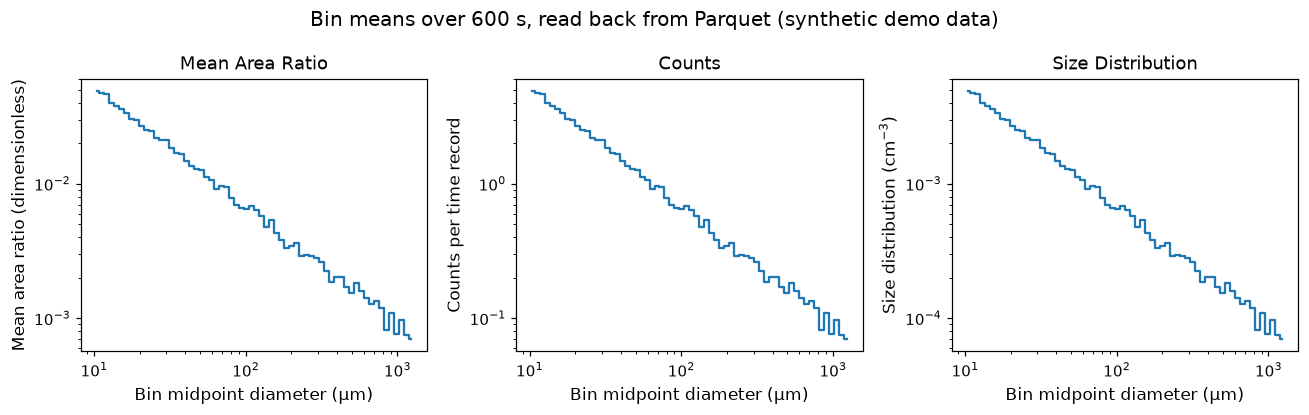

In [23]:
import matplotlib.pyplot as plt

if HAVE_PARQUET and importlib.util.find_spec("pandas") is not None:
    big_df = pq.read_table(big).to_pandas()
    dims = big.stem.split("__")
    bin_dim = next(d for d in dims if big_df[d].nunique() == N_BIN)
    values = [c for c in big_df.columns if c not in dims]
    print(f"{big.name}: {len(big_df)} rows, grouped by {bin_dim}; variables {values}")
    mids = (edges[:-1] + edges[1:]) / 2
    axis_label = {
        "Mean Area Ratio": "Mean area ratio (dimensionless)",
        "Counts": "Counts per time record",
        "Size Distribution cm-3": "Size distribution (cm$^{-3}$)",
    }
    plt.rcParams.update({"font.size": 10, "legend.fontsize": 10})
    fig, axes = plt.subplots(1, len(values), figsize=(4 * len(values), 3.8), squeeze=False)
    for ax, var in zip(axes[0], values):
        mean = big_df.groupby(bin_dim)[var].mean().to_numpy()
        ax.loglog(mids * 1000, np.where(mean > 0, mean, np.nan), drawstyle="steps-mid")
        ax.set_xlabel("Bin midpoint diameter (µm)")
        ax.set_ylabel(axis_label.get(var, var))
        ax.set_title(var.replace(" cm-3", ""))
    fig.suptitle("Bin means over 600 s, read back from Parquet (synthetic demo data)")
    fig.tight_layout()
    plt.show()
else:
    print("pyarrow or pandas is not installed; skipping the plot.")

*Figure 1. The mean over the 600 s of each per-bin variable in the Parquet export, one panel per variable because each has its own unit. Bins with a zero mean are not drawn on the logarithmic axes.*

## Summary

- `export_parquet` copies the attributed export into one long-form Parquet file per dimension
  tuple, with attributes kept as schema metadata.
- Every value reads back identical to the netCDF source, dtype included.
- The tables group and plot with pandas directly; netCDF stays the default output.